<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/06_Android_Malware_Detection/QSVM_AndroidMalware_Mohandass2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Noise-aware quantum-kernel SVM for Android malware detection: Mohandass, S and M (2026) step by step

This notebook re-implements, runs and checks the method of

> Gokulakrishnan Mohandass, Monish S and Kowsigan M, "Noise-Aware Hybrid Classical-Quantum Framework for Android Malware
> Detection", *2026 International Conference on Electronic Systems and Intelligent Computing (ICESIC)*, IEEE, 2026.
> DOI 10.1109/ICESIC67389.2026.11496523. Code: `github.com/AGRIMKNIGHT/qsvm-malware-code` (Qiskit + scikit-learn scripts).

The paper is a small, honest negative result: a quantum-kernel SVM (QSVM) on a 4-qubit `ZZFeatureMap` is compared with a
classical RBF-SVM on the same four principal components of the TUANDROMD Android-malware feature set, and the quantum
kernel is additionally estimated under simulated depolarizing gate noise and readout noise (Qiskit Aer). The classical SVM
wins (0.904 accuracy vs 0.837 for the ideal QSVM), the QSVM degrades further as the noise grows (0.765 at p = 0.10), and
the paper says so.

**What the notebook does.** It downloads TUANDROMD (4,465 apps x 241 binary permission / API-call features) from the UCI
repository, draws the paper's stratified 150-app subset (seed 42), standardises and reduces it to four principal
components (fitted on the training split only), trains the paper's classical baselines (RBF-SVM with scikit-learn
defaults, random forest, XGBoost, logistic regression) and the QSVM with an exact fidelity kernel, then repeats the QSVM with
the paper's noise model, depolarizing probability `p` on every single-qubit rotation, `2p` on every CX, and a readout bit
flip with probability `p`, for `p` in {0, 0.01, 0.03, 0.05, 0.10}, computing every kernel entry from a noisy Aer
density-matrix simulation of the compute-uncompute circuit with 1,024 shots. The paper's PCA-component ablation (2, 3, 4, 6
components) and its paired statistical tests are repeated, and the last section puts Tables I-III of the paper next to our
numbers with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs
pinned Qiskit packages; if Colab asks to restart the session, restart and run all again. No GPU and no IBM Quantum account
are needed.

**Runtime.** `FAST_MODE = True` (one seed, noise levels 0 / 0.03 / 0.10, both angle encodings) takes about 5 minutes on a
laptop CPU; `FAST_MODE = False` (the paper's five seeds and five noise levels, both encodings, about 500,000 noisy 4-qubit
circuits) takes 30-45 minutes. The committed notebook contains the outputs of the run stated in Section 0.

**What you get at the end.** Accuracy, precision, recall, F1, false-negative rate, false-positive rate and AUC
(mean +- std over seeds) of the classical models, of the ideal QSVM and of the noisy QSVM at every noise level, kernel
build times, the paper's Figures 2-5 redrawn from your own run, kernel heat-maps at increasing noise, and a table with one
verdict per number the paper reports.

## The paper in one page

**Problem.** Decide whether an Android app is malware or goodware from static features (requested permissions and API
calls). The paper's question is not "is the QSVM better" but "does a QSVM survive realistic NISQ noise, and what happens
to its false-negative rate" (an undetected malware sample is the costly error).

**Data (Section III.A).** TUANDROMD (Tezpur University Android Malware Dataset; Borah, Bhattacharyya and Kalita, 2020):
4,465 apps, 241 binary features, labels `malware` / `goodware`. A stratified subset of 150 apps (120 malware, 30 goodware)
is drawn with random seed 42 because the fidelity kernel costs one circuit per pair of apps.

**Preprocessing (Section III.B-C).** Zero-mean / unit-variance standardisation of all 241 features, PCA to 4 components
(= 4 qubits) keeping 59.4 % of the variance (PC1 36.8 %, PC2 9.4 %, PC3 7.6 %, PC4 5.6 %). Stratified 70 : 30 train/test
split, repeated for the seeds {0, 21, 42, 63, 84}; results as mean +- std.

**Models (Section IV).** Classical: `SVC(kernel="rbf", C=1, gamma="scale")` on the 4 PCA scores, plus random forest,
XGBoost and logistic regression (Fig. 4, no numbers). Quantum: `ZZFeatureMap(4, reps=2, entanglement="linear")`,
fidelity kernel $K(x_i, x_j) = |\langle\phi(x_i)|\phi(x_j)\rangle|^2$, Gram matrix clipped to be positive semi-definite,
`SVC(kernel="precomputed")`. Noise (Section IV.D, Qiskit Aer): depolarizing error with probability `p` on the rotation
gates (u1, u2, u3, rx, ry, rz), `2p` on CX, and a readout bit flip with probability `p`; `p` in {0, 0.01, 0.03, 0.05, 0.10}.
Metrics: accuracy, precision, recall, F1, FNR = FN / (FN + TP), FPR, AUC.

**Claims.**

| Where | Claim |
|---|---|
| Table I | Classical SVM: Acc 0.904, F1 0.926, FNR 0.056, AUC 0.950. QSVM p = 0.00: 0.837 / 0.882 / 0.083 / 0.890. QSVM p = 0.03: 0.801 / 0.849 / 0.111 / 0.840. QSVM p = 0.10: 0.765 / 0.818 / 0.139 / 0.810 |
| Fig. 2 / V.A | QSVM accuracy 83-85 % ideal, falls to 76-80 % at p = 0.10; classical SVM 90-91 %, unaffected |
| Fig. 3 / V.B | Classical FNR 5-6 %; QSVM FNR rises with moderate noise; at p = 0.10 about 5 of 36 malware missed (13.9 %); "extreme noise might decrease the FNR" at the price of false positives |
| Fig. 4 / V.C | Classical SVM best, then random forest and XGBoost; QSVM does not outperform any classical model |
| Table II / V.D | Accuracy vs PCA components 2 / 3 / 4 / 6: classical 0.842 / 0.881 / 0.904 / 0.921, QSVM 0.783 / 0.817 / 0.837 / 0.865 |
| Table III / V.E | Paired t-test over the 5 runs: t = 3.42, p = 0.012, Cohen's d = 1.21; Wilcoxon statistic 0.00, p = 0.031 |

## What follows the paper and what had to be chosen

The paper and its public code fix almost everything. Two things in the code differ from the paper's text, and two
things the paper does silently are changed here for methodological reasons; every such point is marked `# CHOICE:` in the
code.

| Item | Paper (text / code) | This notebook |
|---|---|---|
| Dataset | TUANDROMD, `TUANDROMD.csv` read locally | same file, downloaded from the UCI repository (id 855) with `ucimlrepo` as fallback; the one row with an empty label is dropped (4,464 apps) |
| Subset | 150 apps, stratified, seed 42 (`train_test_split(train_size=150)`) | identical call |
| Scaling and PCA | code: `StandardScaler` and `PCA(4)` fitted on all 150 apps **before** the split (59.4 % variance) | fitted on the training split of each seed only (`# CHOICE`, no test leakage); the paper's all-150 variance numbers are reproduced separately as a check |
| Angles fed to the feature map | code: the raw PCA scores (range about -10 ... +40) | `ANGLE_MODE = "paper"`: the same raw scores; `ANGLE_MODE = "minmax"`: scores mapped to [0, pi] on the training split, times a bandwidth `SCALE` chosen on an inner validation split (`# CHOICE`, the standard quantum-kernel practice). Both are run and reported |
| Feature map | text: ZZFeatureMap, 4 qubits, reps = 2, linear; code: reps = 2 in the noiseless script, **reps = 1** in the noise script | reps = 2 everywhere (the paper's text), `FM_REPS` in the configuration |
| Ideal kernel | `FidelityQuantumKernel` (exact probabilities) | `FidelityStatevectorKernel`, checked against a hand-computed $|\langle\phi(a)|\phi(b)\rangle|^2$ |
| Noisy kernel | old `QuantumKernel(quantum_instance=AerSimulator(noise_model), shots=1024)`: compute-uncompute circuit, probability of all-zeros, diagonal set to 1 | the same circuit transpiled for Aer (u1 / u2 / cx), exact noisy density-matrix probabilities, the readout error applied as a stochastic matrix, 1,024-shot binomial sampling; diagonal 1; checked against Aer's own shot counts with the full noise model |
| PSD correction | eigenvalue clipping at 1e-10 (`make_psd`) | identical function, applied to the training Gram matrix |
| Noise levels, seeds | {0, 0.01, 0.03, 0.05, 0.10}; seeds {0, 21, 42, 63, 84} | the same in `FAST_MODE = False`; {0, 0.03, 0.10} and seed 42 in `FAST_MODE = True` |
| SVM | `C = 1`, `gamma = "scale"`, no tuning | identical; `C = 1` for the QSVM too |
| Other baselines | random forest, XGBoost, logistic regression (no hyper-parameters given) | `RandomForestClassifier(200)`, `XGBClassifier(200)`, `LogisticRegression` (`# CHOICE`), plus an RBF-SVM on all 241 standardised features to show what PCA costs |
| AUC | from `decision_function` (classical) / `predict_proba` (QSVM noiseless script) | `decision_function` for both SVMs, `predict_proba` for the tree and linear models |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy, matplotlib, xgboost.
# The pip line runs on Colab (or wherever qiskit-machine-learning is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc ucimlrepo
    print("Qiskit installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning already present; skipping pip install.")

qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: one seed, three noise levels (about 5 min). False: the paper's 5 seeds x 5 noise levels (30-45 min).
SEED        = 42             # paper: random seed 42 for the 150-app subset and for PCA
SUBSET_SEED = 42             # paper: stratified 150-app subset drawn with random_state = 42
N_SUBSET    = 150            # paper: 150 apps (120 malware, 30 goodware)
TEST_SIZE   = 0.30           # paper: 70 : 30 stratified split
N_QUBITS    = 4              # paper: 4 principal components = 4 qubits
FM_REPS     = 2              # paper text: ZZFeatureMap with reps = 2 (the public noise script uses reps = 1)
ENTANGLEMENT = "linear"      # paper: linear entanglement
SVM_C       = 1.0            # paper: scikit-learn defaults, no tuning
SVM_GAMMA   = "scale"
SHOTS       = 1024           # paper's code: AerSimulator shots = 1024 for the noisy kernel
PSD_EPS     = 1e-10          # paper's code: eigenvalues below 1e-10 are clipped to 1e-10
PCA_GRID    = [2, 3, 4, 6]   # paper Table II: PCA component counts
ANGLE_MODES = ["paper", "minmax"]        # "paper": raw PCA scores as angles (the paper's code); "minmax": [0, pi] x SCALE  (CHOICE)
SCALE_GRID  = [0.05, 0.1, 0.25, 0.5, 1.0]  # CHOICE: bandwidth candidates for ANGLE_MODE = "minmax", chosen on an inner validation split
VAL_FRACTION = 0.25          # inner validation split of the training rows used for that choice (no test data involved)
if FAST_MODE:
    SEEDS        = [42]                         # paper: {0, 21, 42, 63, 84}
    NOISE_LEVELS = [0.0, 0.03, 0.10]            # paper: {0, 0.01, 0.03, 0.05, 0.10}
    N_AER_CHECK  = 20                           # pairs on which the kernel route is checked against Aer's own shot counts
else:
    SEEDS        = [0, 21, 42, 63, 84]
    NOISE_LEVELS = [0.0, 0.01, 0.03, 0.05, 0.10]
    N_AER_CHECK  = 60
AER_PARALLEL_EXPERIMENTS = 2   # CHOICE: Aer runs this many kernel circuits in parallel (Colab CPUs have 2 cores)
AER_CHUNK   = 4000             # circuits per Aer call
DATA_DIR    = "data"
DATA_URLS   = ["https://archive.ics.uci.edu/static/public/855/tuandromd+(tezpur+university+android+malware+dataset).zip"]
DATA_PATH   = ""               # optional: path to a local TUANDROMD.csv (leave empty to download)
IBM_TOKEN   = ""               # not needed: every quantum computation here is simulated, as in the paper

In [3]:
import os, io, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy import stats

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)
try:
    from xgboost import XGBClassifier
    HAVE_XGB = True
except ImportError:
    HAVE_XGB = False

import qiskit, qiskit_aer, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.utils import algorithm_globals

algorithm_globals.random_seed = SEED
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", HAVE_XGB)
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "| noise levels:", NOISE_LEVELS, "| angle modes:", ANGLE_MODES)

qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-machine-learning 0.9.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | xgboost True
FAST_MODE = False | seeds: [0, 21, 42, 63, 84] | noise levels: [0.0, 0.01, 0.03, 0.05, 0.1] | angle modes: ['paper', 'minmax']


## 1. The TUANDROMD dataset

TUANDROMD (Borah, Bhattacharyya and Kalita, 2020) describes 4,465 Android apps by 241 binary features: 1 if the app
requests a given permission (`SEND_SMS`, `READ_CONTACTS`, ...) or calls a given API (`TelephonyManager.getDeviceId`,
`Runtime.exec`, ...), 0 otherwise. 3,565 apps are malware (from the Drebin / AndroZoo collections) and 899 are goodware;
one row has an empty label and is dropped. The file is 2 MB; it is downloaded from the UCI Machine Learning Repository
(dataset 855) and cached in `DATA_DIR`. Set `DATA_PATH` to use a local copy.

In [4]:
def load_tuandromd():
    cached = os.path.join(DATA_DIR, "TUANDROMD.csv")
    if DATA_PATH:
        return pd.read_csv(DATA_PATH)
    if os.path.exists(cached):
        print("using cached", cached); return pd.read_csv(cached)
    import requests
    for url in DATA_URLS:
        try:
            r = requests.get(url, timeout=120, headers={"User-Agent": "Mozilla/5.0"}); r.raise_for_status()
            with zipfile.ZipFile(io.BytesIO(r.content)) as z:
                name = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
                open(cached, "wb").write(z.read(name))
            print("downloaded TUANDROMD.csv from", url.split("/")[2]); return pd.read_csv(cached)
        except Exception as e:
            print("failed:", url, type(e).__name__, e)
    from ucimlrepo import fetch_ucirepo                          # fallback: the same dataset through the UCI API
    ds = fetch_ucirepo(id=855)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1); df.to_csv(cached, index=False)
    print("downloaded TUANDROMD through ucimlrepo"); return df

t0 = time.time()
raw = load_tuandromd()
LABEL_COL = [c for c in raw.columns if c.lower() in ("label", "class", "malware")][0]
raw = raw.dropna(subset=[LABEL_COL]).reset_index(drop=True)
FEATURES = [c for c in raw.columns if c != LABEL_COL]
X_all = raw[FEATURES].astype(float).fillna(0.0).to_numpy()          # paper's code: np.nan_to_num on the numeric features
y_all = (raw[LABEL_COL].astype(str).str.lower() == "malware").astype(int).to_numpy()   # malware = 1 (positive class), goodware = 0
print(f"loaded in {time.time()-t0:.1f} s: {len(raw):,} apps x {len(FEATURES)} features (paper: 4,465 x 241)")
print("labels:", {"malware (1)": int(y_all.sum()), "goodware (0)": int((y_all == 0).sum())})
print("feature values are binary:", bool(np.isin(X_all, [0.0, 1.0]).all()), "| mean features set per app:", X_all.sum(axis=1).mean().round(1))
print("ten most frequent features:", pd.Series(X_all.mean(axis=0), index=FEATURES).sort_values(ascending=False).head(10).round(3).to_dict())
raw[FEATURES[:6] + [LABEL_COL]].head(5)

using cached data\TUANDROMD.csv


loaded in 0.7 s: 4,464 apps x 241 features (paper: 4,465 x 241)
labels: {'malware (1)': 3565, 'goodware (0)': 899}
feature values are binary: True | mean features set per app: 14.4
ten most frequent features: {'WAKE_LOCK': 0.886, 'RECEIVE_BOOT_COMPLETED': 0.844, 'INTERNET': 0.734, 'GET_TASKS': 0.641, 'ACCESS_NETWORK_STATE': 0.596, 'Ljava/lang/reflect/Method;->invoke': 0.55, 'READ_PHONE_STATE': 0.535, 'Ljavax/crypto/Cipher;->doFinal': 0.517, 'KILL_BACKGROUND_PROCESSES': 0.504, 'WRITE_EXTERNAL_STORAGE': 0.441}


,ACCESS_ALL_DOWNLOADS,ACCESS_CACHE_FILESYSTEM,ACCESS_CHECKIN_PROPERTIES,ACCESS_COARSE_LOCATION,ACCESS_COARSE_UPDATES,ACCESS_FINE_LOCATION,Label
0,0.0,0.0,0.0,0.0,0.0,0.0,malware
1,0.0,0.0,0.0,0.0,0.0,0.0,malware
2,0.0,0.0,0.0,0.0,0.0,0.0,malware
3,0.0,0.0,0.0,0.0,0.0,0.0,malware
4,0.0,0.0,0.0,0.0,0.0,0.0,malware


## 2. The paper's 150-app subset and the 70 : 30 splits

A fidelity kernel needs one circuit per pair of apps, so the paper works with a stratified subset of 150 apps drawn with
`train_test_split(train_size=150, stratify=y, random_state=42)`: 120 malware and 30 goodware, the same 80 : 20 ratio as
the full file. Each experiment then splits those 150 apps 70 : 30 with stratification for the seeds {0, 21, 42, 63, 84}
(105 training / 45 test apps, 36 of the 45 test apps being malware, which is where the paper's "5 out of 36" comes from).
`FAST_MODE` uses seed 42 only.

In [5]:
X_sub, _, y_sub, _ = train_test_split(X_all, y_all, train_size=N_SUBSET, stratify=y_all, random_state=SUBSET_SEED)   # paper's call
print(f"subset: {X_sub.shape[0]} apps, malware {int(y_sub.sum())}, goodware {int((y_sub == 0).sum())} (paper: 120 / 30)")

def split(seed):
    '''The paper's 70 : 30 stratified split of the 150-app subset for one seed; returns row indices.'''
    idx = np.arange(len(y_sub))
    return train_test_split(idx, test_size=TEST_SIZE, stratify=y_sub, random_state=seed)

def inner_split(y_tr, seed):
    '''Stratified split of the TRAINING rows into inner-train / inner-validation, used only to choose SCALE.'''
    return train_test_split(np.arange(len(y_tr)), test_size=VAL_FRACTION, stratify=y_tr, random_state=seed)

for s in SEEDS:
    tr, te = split(s)
    print(f"seed {s:2d}: train {len(tr)} (malware {int(y_sub[tr].sum())}), test {len(te)} (malware {int(y_sub[te].sum())}, goodware {int((y_sub[te] == 0).sum())})")

subset: 150 apps, malware 120, goodware 30 (paper: 120 / 30)
seed  0: train 105 (malware 84), test 45 (malware 36, goodware 9)
seed 21: train 105 (malware 84), test 45 (malware 36, goodware 9)
seed 42: train 105 (malware 84), test 45 (malware 36, goodware 9)
seed 63: train 105 (malware 84), test 45 (malware 36, goodware 9)
seed 84: train 105 (malware 84), test 45 (malware 36, goodware 9)


## 3. Standardisation, PCA and the angles that enter the circuit

The paper standardises the 241 features and keeps four principal components. Its public code fits the scaler and the PCA
on all 150 apps and splits afterwards, which lets the test apps influence the projection; the notebook fits both on the
training split of each seed (`# CHOICE`). The cell below also runs the paper's all-150 variant once, only to check its
variance figures (59.4 %; PC1 36.8 %, PC2 9.4 %, PC3 7.6 %, PC4 5.6 %).

The PCA scores are what the paper's code feeds to the `ZZFeatureMap` as rotation angles (`ANGLE_MODE = "paper"`). They
range from about -10 to +40, far outside $[0, \pi]$, so two apps that differ slightly already map to nearly orthogonal
quantum states. The notebook therefore also runs the usual practice (`ANGLE_MODE = "minmax"`): map each component to
$[0, \pi]$ with a min-max scaler fitted on the training split (test values clipped) and multiply by a bandwidth `SCALE`
chosen on an inner validation split of the training rows in Section 5. The classical models always receive the raw PCA
scores, as in the paper.

seed  0: PCA on the 105 training apps keeps 61.2% (37.3%, 9.4%, 8.1%, 6.4%) | PCA score range train [-11.2, 44.3], std per component [6.32 3.17 2.94 2.61]
seed 21: PCA on the 105 training apps keeps 62.8% (39.2%, 10.5%, 8.1%, 5.1%) | PCA score range train [-5.5, 45.4], std per component [6.48 3.35 2.94 2.33]
seed 42: PCA on the 105 training apps keeps 64.1% (41.3%, 9.4%, 7.4%, 6.0%) | PCA score range train [-10.9, 37.8], std per component [6.61 3.16 2.81 2.52]
seed 63: PCA on the 105 training apps keeps 62.7% (39.1%, 9.4%, 8.1%, 6.1%) | PCA score range train [-10.3, 37.1], std per component [6.53 3.19 2.98 2.58]
seed 84: PCA on the 105 training apps keeps 61.2% (36.4%, 10.2%, 8.4%, 6.2%) | PCA score range train [-11.3, 43.8], std per component [6.3  3.34 3.02 2.59]
PCA on all 150 apps (paper's code): 59.4% (36.8%, 9.4%, 7.6%, 5.6%); paper: 59.4 % (36.8, 9.4, 7.6, 5.6)
constant features in the seed-0 training split: 134 of 241 (they carry no information for PCA)


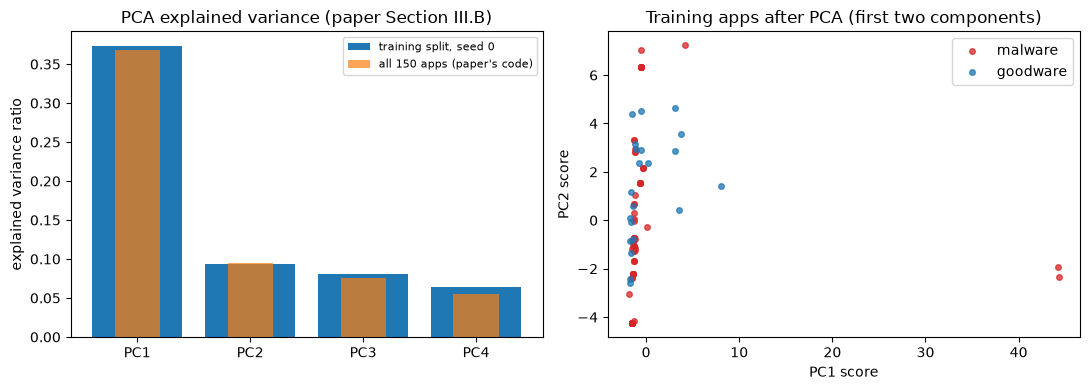

In [6]:
def prepare(seed, n_components=N_QUBITS):
    '''Everything fitted on the training split only. Returns PCA scores (classical input and 'paper' angles),
    the min-max [0, pi] version of them, the standardised 241-feature matrices and the fitted PCA.'''
    tr, te = split(seed)
    scaler = StandardScaler().fit(X_sub[tr])                                   # paper: zero-mean, unit-variance
    Z_tr, Z_te = scaler.transform(X_sub[tr]), scaler.transform(X_sub[te])
    pca = PCA(n_components=n_components, random_state=SEED).fit(Z_tr)          # CHOICE: fitted on the training split only
    P_tr, P_te = pca.transform(Z_tr), pca.transform(Z_te)
    mm = MinMaxScaler((0.0, np.pi)).fit(P_tr)                                  # CHOICE: [0, pi] angles for ANGLE_MODE = "minmax"
    M_tr, M_te = mm.transform(P_tr), np.clip(mm.transform(P_te), 0.0, np.pi)
    return dict(tr=tr, te=te, y_tr=y_sub[tr], y_te=y_sub[te], P_tr=P_tr, P_te=P_te, M_tr=M_tr, M_te=M_te,
                Z_tr=Z_tr, Z_te=Z_te, pca=pca)

def angles(d, mode, scale=1.0):
    '''Angle matrices (train, test) for one encoding mode.'''
    if mode == "paper":
        return d["P_tr"], d["P_te"]                      # paper's code: raw PCA scores
    return scale * d["M_tr"], scale * d["M_te"]          # CHOICE: [0, pi] x SCALE

prepared = {s: prepare(s) for s in SEEDS}
for s, d in prepared.items():
    ev = d["pca"].explained_variance_ratio_
    print(f"seed {s:2d}: PCA on the 105 training apps keeps {ev.sum():.1%} ({', '.join(f'{v:.1%}' for v in ev)}) | "
          f"PCA score range train [{d['P_tr'].min():.1f}, {d['P_tr'].max():.1f}], std per component {np.round(d['P_tr'].std(axis=0), 2)}")

# the paper's code: scaler + PCA on all 150 apps (reproduces its variance figures; not used for any model here)
ev150 = PCA(n_components=N_QUBITS, random_state=SEED).fit(StandardScaler().fit_transform(X_sub)).explained_variance_ratio_
print(f"PCA on all 150 apps (paper's code): {ev150.sum():.1%} ({', '.join(f'{v:.1%}' for v in ev150)}); paper: 59.4 % (36.8, 9.4, 7.6, 5.6)")
n_const = int((X_sub[prepared[SEEDS[0]]['tr']].std(axis=0) == 0).sum())
print(f"constant features in the seed-{SEEDS[0]} training split: {n_const} of {len(FEATURES)} (they carry no information for PCA)")

d0 = prepared[SEEDS[0]]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar([f"PC{i+1}" for i in range(N_QUBITS)], d0["pca"].explained_variance_ratio_, label=f"training split, seed {SEEDS[0]}")
axes[0].bar([f"PC{i+1}" for i in range(N_QUBITS)], ev150, width=0.4, alpha=0.7, label="all 150 apps (paper's code)")
axes[0].set_ylabel("explained variance ratio"); axes[0].set_title("PCA explained variance (paper Section III.B)"); axes[0].legend(fontsize=8)
for lab, name, c in [(1, "malware", "tab:red"), (0, "goodware", "tab:blue")]:
    m = d0["y_tr"] == lab
    axes[1].scatter(d0["P_tr"][m, 0], d0["P_tr"][m, 1], s=16, c=c, label=name, alpha=0.75)
axes[1].set_xlabel("PC1 score"); axes[1].set_ylabel("PC2 score"); axes[1].set_title("Training apps after PCA (first two components)"); axes[1].legend()
plt.tight_layout(); plt.show()

## 4. Classical baselines on the same four principal components

The paper's reference model is `SVC(kernel="rbf")` with scikit-learn's defaults (`C = 1`, `gamma = "scale"`), deliberately
untuned. Random forest, XGBoost and logistic regression appear in Fig. 4 without numbers or hyper-parameters. All of them
are trained on the four PCA scores of every seed and reported as mean +- std, with the metrics of Section IV.E: accuracy,
precision, recall and F1 for the malware class, FNR = FN / (FN + TP), FPR = FP / (FP + TN) and AUC. An RBF-SVM on all 241
standardised features is added (not in the paper) to show what the 241 -> 4 bottleneck costs.

In [7]:
METRICS = ["accuracy", "precision", "recall", "f1", "fnr", "fpr", "auc"]

def all_metrics(y_true, y_pred, score=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    out = dict(accuracy=accuracy_score(y_true, y_pred),
               precision=precision_score(y_true, y_pred, zero_division=0),
               recall=recall_score(y_true, y_pred, zero_division=0),
               f1=f1_score(y_true, y_pred, zero_division=0),
               fnr=fn / max(fn + tp, 1), fpr=fp / max(fp + tn, 1),
               auc=roc_auc_score(y_true, score) if score is not None else np.nan,
               fn=int(fn), tp=int(tp), fp=int(fp), tn=int(tn))
    return out

def classical_models():
    models = {"Classical SVM (rbf)": SVC(kernel="rbf", C=SVM_C, gamma=SVM_GAMMA, random_state=SEED),   # paper's baseline
              "RandomForest": RandomForestClassifier(n_estimators=200, random_state=SEED),            # CHOICE: 200 trees
              "LogisticRegression": LogisticRegression(max_iter=2000, random_state=SEED)}
    if HAVE_XGB:
        models["XGBoost"] = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, random_state=SEED, verbosity=0)   # CHOICE
    return models

def score_of(model, X):
    return model.decision_function(X) if hasattr(model, "decision_function") else model.predict_proba(X)[:, 1]

baseline_rows, baseline_preds = [], {}
for s in SEEDS:
    d = prepared[s]
    for name, model in classical_models().items():
        t0 = time.perf_counter(); model.fit(d["P_tr"], d["y_tr"]); t_fit = time.perf_counter() - t0
        pred = model.predict(d["P_te"])
        baseline_rows.append(dict(seed=s, model=name, inputs="4 PCA scores", fit_s=t_fit, **all_metrics(d["y_te"], pred, score_of(model, d["P_te"]))))
        baseline_preds[(s, name)] = pred
    model = SVC(kernel="rbf", C=SVM_C, gamma=SVM_GAMMA, random_state=SEED).fit(d["Z_tr"], d["y_tr"])
    baseline_rows.append(dict(seed=s, model="Classical SVM (rbf), all 241 features", inputs="241 standardised features", fit_s=np.nan,
                              **all_metrics(d["y_te"], model.predict(d["Z_te"]), model.decision_function(d["Z_te"]))))
baseline_df = pd.DataFrame(baseline_rows)
baseline_summary = baseline_df.groupby("model")[METRICS].agg(["mean", "std"]).round(3)
print(f"Classical models, mean +- std over {len(SEEDS)} seed(s) (paper Table I: SVM acc 0.904, F1 0.926, FNR 0.056, AUC 0.950):")
display(baseline_summary)
majority = pd.Series([max(prepared[s]['y_te'].mean(), 1 - prepared[s]['y_te'].mean()) for s in SEEDS]).mean()
print(f"majority-class ('everything is malware') accuracy on the test split: {majority:.3f}, FNR 0, FPR 1")

Classical models, mean +- std over 5 seed(s) (paper Table I: SVM acc 0.904, F1 0.926, FNR 0.056, AUC 0.950):


accuracy        precision        recall            f1           fnr           fpr           auc       
                                          mean    std      mean    std   mean    std   mean    std   mean    std   mean    std   mean    std
model                                                                                                                                       
Classical SVM (rbf)                      0.911  0.016     0.917  0.020  0.978  0.012  0.946  0.009  0.022  0.012  0.356  0.093  0.948  0.034
Classical SVM (rbf), all 241 features    0.947  0.034     0.974  0.044  0.961  0.015  0.967  0.020  0.039  0.015  0.111  0.192  0.993  0.008
LogisticRegression                       0.929  0.019     0.932  0.021  0.983  0.015  0.957  0.011  0.017  0.015  0.289  0.099  0.954  0.023
RandomForest                             0.956  0.016     0.958  0.029  0.989  0.015  0.973  0.009  0.011  0.015  0.178  0.127  0.973  0.037
XGBoost                                  0.964  0.020     0.973  0.019  0.983  0.015  0.978  0.012  0.017  0.015  0.111  0.079  0.984  0.023

majority-class ('everything is malware') accuracy on the test split: 0.800, FNR 0, FPR 1


## 5. The ZZFeatureMap and the ideal fidelity kernel

The quantum part of the paper is the feature map of Havlicek et al. (2019) that Qiskit ships as `ZZFeatureMap`
(`zz_feature_map` in Qiskit 2): per repetition a Hadamard on every qubit, a phase rotation $P(2x_i)$ on qubit $i$, and
$P(2(\pi - x_i)(\pi - x_j))$ between the neighbouring qubits $i, j$ through two CX gates (linear entanglement). With
`reps = 2` the circuit on four qubits has 8 H, 14 P and 12 CX gates. The kernel entry is the fidelity
$K_{ij} = |\langle\phi(x_i)|\phi(x_j)\rangle|^2$.

Ideally (no noise, no shots) the kernel is computed from the statevectors, which is what the paper's noiseless script
does. The cell builds the circuit, draws it, computes the Gram matrix with `FidelityStatevectorKernel` and checks it against
the same quantity computed by hand from `Statevector`. The paper's `make_psd` (clip eigenvalues below 1e-10) is defined
here and used on every training Gram matrix, as the paper does.

In [8]:
feature_map = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement=ENTANGLEMENT)
ideal_kernel = FidelityStatevectorKernel(feature_map=feature_map)
print("ZZFeatureMap gates:", dict(feature_map.count_ops()), "| depth", feature_map.depth(), "| parameters", [p.name for p in feature_map.parameters])
try:
    fig = feature_map.draw("mpl", fold=-1); fig.suptitle(f"ZZFeatureMap, {N_QUBITS} qubits, reps = {FM_REPS}, {ENTANGLEMENT} entanglement", y=1.02); plt.show()
except Exception as e:
    print(feature_map.draw("text", fold=-1))

def make_psd(K, eps=PSD_EPS):
    '''The paper's PSD correction: clip eigenvalues below eps (noise and shot sampling can make the Gram matrix indefinite).'''
    w, V = np.linalg.eigh(K)
    return np.real(V @ np.diag(np.maximum(w, eps)) @ V.T)

def fidelity_by_hand(A, B):
    S_a = np.array([Statevector(feature_map.assign_parameters(a)).data for a in A])
    S_b = np.array([Statevector(feature_map.assign_parameters(b)).data for b in B])
    return np.abs(S_a @ S_b.conj().T) ** 2

d0 = prepared[SEEDS[0]]; A_tr, A_te = angles(d0, "paper")
t0 = time.perf_counter(); K_tr0 = ideal_kernel.evaluate(A_tr); K_te0 = ideal_kernel.evaluate(A_te, A_tr); t_k = time.perf_counter() - t0
K_hand = fidelity_by_hand(A_tr[:20], A_tr[:20])
assert np.allclose(K_tr0[:20, :20], K_hand, atol=1e-8)
print(f"exact kernel for seed {SEEDS[0]} (raw PCA angles): train {K_tr0.shape}, test {K_te0.shape} in {t_k:.1f} s; agrees with the hand-computed |<phi(a)|phi(b)>|^2 (np.allclose)")
off = K_tr0[~np.eye(len(K_tr0), dtype=bool)]
print(f"mean off-diagonal kernel value {off.mean():.3f}, median {np.median(off):.3f}, share above 0.5: {(off > 0.5).mean():.1%}  (an identity-like kernel means every app looks unlike every other)")
print("smallest eigenvalue of the exact training Gram matrix:", np.linalg.eigvalsh(K_tr0).min().round(8), "-> make_psd changes it by", np.abs(make_psd(K_tr0) - K_tr0).max().round(10))

ZZFeatureMap gates: {'p': 14, 'cx': 12, 'h': 8} | depth 19 | parameters ['x[0]', 'x[1]', 'x[2]', 'x[3]']


exact kernel for seed 0 (raw PCA angles): train (105, 105), test (45, 105) in 0.7 s; agrees with the hand-computed |<phi(a)|phi(b)>|^2 (np.allclose)
mean off-diagonal kernel value 0.114, median 0.051, share above 0.5: 4.3%  (an identity-like kernel means every app looks unlike every other)
smallest eigenvalue of the exact training Gram matrix: -0.0 -> make_psd changes it by 1e-10


### 5b. Choosing the bandwidth for `ANGLE_MODE = "minmax"` on training data only

For the second encoding the angles are `SCALE` times the min-max-scaled scores. `SCALE` is picked per seed with the exact
kernel on an inner 75 : 25 split of the training apps (best inner-validation accuracy, ties to the smaller scale); the
test split is never touched. The same scale is then used at every noise level for that seed.

In [9]:
best_scale, sweep_rows = {}, []
for s in SEEDS:
    d = prepared[s]; itr, ival = inner_split(d["y_tr"], s)
    best = None
    for scale in SCALE_GRID:
        A_tr, _ = angles(d, "minmax", scale)
        K = ideal_kernel.evaluate(A_tr)
        svc = SVC(kernel="precomputed", C=SVM_C).fit(make_psd(K[np.ix_(itr, itr)]), d["y_tr"][itr])
        val_acc = accuracy_score(d["y_tr"][ival], svc.predict(K[np.ix_(ival, itr)]))
        sweep_rows.append(dict(seed=s, scale=scale, inner_val_accuracy=val_acc, mean_offdiag=K[~np.eye(len(K), dtype=bool)].mean()))
        if best is None or val_acc > best[0]:
            best = (val_acc, scale)
    best_scale[s] = best[1]
sweep_df = pd.DataFrame(sweep_rows)
display(sweep_df.pivot(index="scale", columns="seed", values="inner_val_accuracy").round(3))
print("chosen SCALE per seed:", best_scale)

seed,0,21,42,63,84
scale,,,,,
0.05,0.889,0.815,0.926,0.852,0.815
0.10,0.926,0.889,0.963,0.852,0.815
0.25,0.926,0.926,1.000,0.926,0.852
0.50,0.926,0.926,1.000,0.926,0.889
1.00,0.926,0.926,0.852,0.852,0.852


chosen SCALE per seed: {0: 0.1, 21: 0.25, 42: 0.25, 63: 0.25, 84: 0.5}


## 6. The ideal QSVM (paper: "QSVM (0.00)") and the statistical tests of Table III

`SVC(kernel="precomputed", C=1)` on the clipped exact Gram matrix, for every seed and both encodings. Then the paper's
Section V.E: a paired t-test and a Wilcoxon signed-rank test on the per-seed accuracies of the classical SVM and of the
ideal QSVM, plus Cohen's d (mean difference over the standard deviation of the differences).

In [10]:
def qsvm_fit_eval(K_tr, K_te, y_tr, y_te):
    t0 = time.perf_counter(); svc = SVC(kernel="precomputed", C=SVM_C).fit(make_psd(K_tr), y_tr); t_fit = time.perf_counter() - t0
    pred = svc.predict(K_te)
    return pred, dict(fit_s=t_fit, n_support=int(svc.n_support_.sum()), train_accuracy=accuracy_score(y_tr, svc.predict(K_tr)),
                      **all_metrics(y_te, pred, svc.decision_function(K_te)))

ideal_rows, ideal_preds, ideal_kernels = [], {}, {}
for mode in ANGLE_MODES:
    for s in SEEDS:
        d = prepared[s]; scale = best_scale[s] if mode == "minmax" else 1.0
        A_tr, A_te = angles(d, mode, scale)
        t0 = time.perf_counter(); K_tr = ideal_kernel.evaluate(A_tr); K_te = ideal_kernel.evaluate(A_te, A_tr); t_k = time.perf_counter() - t0
        pred, r = qsvm_fit_eval(K_tr, K_te, d["y_tr"], d["y_te"])
        ideal_rows.append(dict(angle_mode=mode, seed=s, scale=scale, kernel_s=t_k, **r))
        ideal_preds[(mode, s)] = pred; ideal_kernels[(mode, s)] = (K_tr, K_te)
ideal_df = pd.DataFrame(ideal_rows)
print(f"Ideal QSVM (exact kernel), mean +- std over {len(SEEDS)} seed(s); paper Table I 'QSVM (0.00)': acc 0.837, F1 0.882, FNR 0.083, AUC 0.890")
display(ideal_df.groupby("angle_mode")[METRICS + ["train_accuracy", "n_support", "kernel_s"]].agg(["mean", "std"]).round(3))
display(ideal_df[["angle_mode", "seed", "scale", "accuracy", "f1", "fnr", "fpr", "auc", "fn", "tp", "fp", "tn"]].round(3))

# paper Table III: paired tests over the seeds, classical SVM vs ideal QSVM (paper's encoding)
svm_acc = baseline_df[baseline_df.model == "Classical SVM (rbf)"].set_index("seed").loc[SEEDS, "accuracy"].to_numpy()
stat_rows = []
for mode in ANGLE_MODES:
    q_acc = ideal_df[ideal_df.angle_mode == mode].set_index("seed").loc[SEEDS, "accuracy"].to_numpy()
    diff = svm_acc - q_acc
    if len(SEEDS) >= 2 and diff.std(ddof=1) > 0:
        t, p_t = stats.ttest_rel(svm_acc, q_acc); d_cohen = diff.mean() / diff.std(ddof=1)
        try:
            w, p_w = stats.wilcoxon(svm_acc, q_acc)
        except ValueError:
            w, p_w = np.nan, np.nan
    else:
        t = p_t = d_cohen = w = p_w = np.nan
    stat_rows.append(dict(qsvm_encoding=mode, mean_svm_acc=svm_acc.mean(), mean_qsvm_acc=q_acc.mean(), mean_gap=diff.mean(),
                          t_statistic=t, t_pvalue=p_t, cohens_d=d_cohen, wilcoxon_statistic=w, wilcoxon_pvalue=p_w))
stats_df = pd.DataFrame(stat_rows)
print("Paper Table III (classical SVM vs ideal QSVM, 5 runs): paired t = 3.42, p = 0.012, Cohen's d = 1.21; Wilcoxon statistic 0.00, p = 0.031")
display(stats_df.round(4))
if len(SEEDS) < 2:
    print("FAST_MODE runs one seed: the paired tests need several seeds (set FAST_MODE = False).")

Ideal QSVM (exact kernel), mean +- std over 5 seed(s); paper Table I 'QSVM (0.00)': acc 0.837, F1 0.882, FNR 0.083, AUC 0.890


accuracy        precision        recall            f1           fnr         fpr           auc        train_accuracy        n_support        kernel_s       
               mean    std      mean    std   mean    std   mean    std   mean    std mean    std   mean    std           mean    std      mean    std     mean    std
angle_mode                                                                                                                                                            
minmax        0.907  0.029     0.908  0.021  0.983  0.015  0.944  0.017  0.017  0.015  0.4  0.099  0.930  0.082          0.949  0.028      33.0  6.364    0.775  0.094
paper         0.822  0.027     0.831  0.021  0.978  0.023  0.898  0.015  0.022  0.023  0.8  0.122  0.887  0.047          0.954  0.014      56.0  2.236    0.717  0.056

,angle_mode,seed,scale,accuracy,f1,fnr,fpr,auc,fn,tp,fp,tn
0,paper,0,1.00,0.844,0.909,0.028,0.667,0.818,1,35,6,3
1,paper,21,1.00,0.844,0.909,0.028,0.667,0.901,1,35,6,3
2,paper,42,1.00,0.822,0.900,0.000,0.889,0.923,0,36,8,1
3,paper,63,1.00,0.822,0.900,0.000,0.889,0.861,0,36,8,1
4,paper,84,1.00,0.778,0.872,0.056,0.889,0.932,2,34,8,1
5,minmax,0,0.10,0.867,0.921,0.028,0.556,0.923,1,35,5,4
6,minmax,21,0.25,0.911,0.946,0.028,0.333,0.960,1,35,3,6
7,minmax,42,0.25,0.889,0.933,0.028,0.444,0.790,1,35,4,5
8,minmax,63,0.25,0.933,0.960,0.000,0.333,0.991,0,36,3,6
9,minmax,84,0.50,0.933,0.960,0.000,0.333,0.985,0,36,3,6


Paper Table III (classical SVM vs ideal QSVM, 5 runs): paired t = 3.42, p = 0.012, Cohen's d = 1.21; Wilcoxon statistic 0.00, p = 0.031


,qsvm_encoding,mean_svm_acc,mean_qsvm_acc,mean_gap,t_statistic,t_pvalue,cohens_d,wilcoxon_statistic,wilcoxon_pvalue
0,paper,0.9111,0.8222,0.0889,7.303,0.0019,3.2660,0.0,0.0625
1,minmax,0.9111,0.9067,0.0044,0.343,0.7489,0.1534,4.0,1.0000


## 7. The noise model and the noisy kernel estimator

On a quantum computer the fidelity $|\langle\phi(x_i)|\phi(x_j)\rangle|^2$ is not read off a statevector; it is
estimated by running the **compute-uncompute circuit** $U_\phi(x_j)^\dagger U_\phi(x_i)|0\rangle$ and counting how often all
qubits are measured as 0. The paper's noise model (Section IV.D, built with Qiskit Aer) adds

* a depolarizing channel $\mathcal{E}(\rho) = (1 - p)\rho + p\, I/2$ after every single-qubit rotation gate (u1, u2, u3, rx,
  ry, rz) and a two-qubit depolarizing channel with probability $2p$ after every CX,
* a readout error that flips each measured bit with probability $p$,

for $p \in \{0, 0.01, 0.03, 0.05, 0.10\}$, with 1,024 shots per kernel entry. Aer transpiles the H and P gates of the
feature map into u2 and u1 gates, so every gate of the circuit is noisy (the 4-qubit compute-uncompute circuit has 16 u2,
28 u1 and 22 CX after transpilation; two CX cancel at the junction).

The kernel route below keeps all of that but avoids simulating one million shots one by one: for every pair the noisy
density matrix is propagated exactly by `AerSimulator(method="density_matrix")`, the readout error is applied as the
$16 \times 16$ stochastic matrix $E^{\otimes 4}$ with $E = \begin{pmatrix}1-p & p\\ p & 1-p\end{pmatrix}$, and the number of
all-zero outcomes among `SHOTS` shots is drawn from the resulting binomial distribution, which is exactly the distribution
of Aer's own counts. The diagonal of the training Gram matrix is set to 1, as `QuantumKernel` / `FidelityQuantumKernel`
do by default (the paper's code inherits this). The cell checks the route against (a) the exact kernel at $p = 0$ and
(b) Aer's own counts with the full noise model, readout included, on `N_AER_CHECK` pairs.

In [11]:
def build_noise_model(p):
    '''Paper Section IV.D: depolarizing p on single-qubit rotations, 2p on CX, readout bit flip p.'''
    nm = NoiseModel()
    if p > 0:
        nm.add_all_qubit_quantum_error(depolarizing_error(p, 1), ["u1", "u2", "u3", "rx", "ry", "rz"])
        nm.add_all_qubit_quantum_error(depolarizing_error(2 * p, 2), ["cx"])
        nm.add_all_qubit_readout_error(ReadoutError([[1 - p, p], [p, 1 - p]]))
    return nm

def readout_matrix(p):
    E = np.array([[1 - p, p], [p, 1 - p]]); M = E
    for _ in range(N_QUBITS - 1):
        M = np.kron(M, E)
    return M                                       # M[k, j] = P(measure k | true outcome j)

# compute-uncompute circuit with two parameter sets a (left sample) and b (right sample)
fm_a = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement=ENTANGLEMENT, parameter_prefix="a")
fm_b = zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement=ENTANGLEMENT, parameter_prefix="b")
cu_circuit = QuantumCircuit(N_QUBITS); cu_circuit.compose(fm_a, inplace=True); cu_circuit.compose(fm_b.inverse(), inplace=True)
cu_probs = cu_circuit.copy(); cu_probs.save_probabilities()          # exact noisy probabilities before readout
cu_meas = cu_circuit.copy(); cu_meas.measure_all()                   # the shot-based circuit the paper's code runs

def make_backend(p):
    return AerSimulator(noise_model=build_noise_model(p), method="density_matrix", seed_simulator=SEED,
                        fusion_enable=False, max_parallel_experiments=AER_PARALLEL_EXPERIMENTS)

# transpile once against a noisy backend (gate set u1 / u2 / cx) and reuse the same circuit at every noise level
pm = generate_preset_pass_manager(optimization_level=1, backend=make_backend(0.01), seed_transpiler=SEED)
t_probs, t_meas = pm.run(cu_probs), pm.run(cu_meas)
print("transpiled compute-uncompute circuit:", dict(t_meas.count_ops()), "| depth", t_meas.depth())

def _binds(circuit, A, B, pairs):
    '''Parameter binds for the circuit: a[k] <- A[i, k], b[k] <- B[j, k] for every (i, j) in pairs.'''
    I = np.array([i for i, _ in pairs]); J = np.array([j for _, j in pairs])
    return {prm: (A[I, int(prm.name[2:-1])] if prm.name.startswith("a") else B[J, int(prm.name[2:-1])]).tolist() for prm in circuit.parameters}

def zero_probabilities(backend, A, B, pairs, p):
    '''P(all qubits read 0) for every pair, with gate noise (Aer density matrix) and readout noise (stochastic matrix).'''
    M = readout_matrix(p); out = np.empty(len(pairs))
    for s in range(0, len(pairs), AER_CHUNK):
        chunk = pairs[s:s + AER_CHUNK]
        res = backend.run(t_probs, parameter_binds=[_binds(t_probs, A, B, chunk)], shots=1).result()
        probs = np.array([res.data(k)["probabilities"] for k in range(len(chunk))])
        out[s:s + len(chunk)] = np.clip((probs @ M.T)[:, 0], 0.0, 1.0)      # clip float round-off (probabilities like 1+1e-16)
    return out

def noisy_kernel(A, B, p, backend, shots=SHOTS, rng=rng):
    '''Noisy fidelity kernel between rows of A and rows of B (B is None for the symmetric training Gram matrix).'''
    if B is None:
        n = len(A); K = np.ones((n, n)); iu = np.triu_indices(n, k=1); pairs = list(zip(iu[0], iu[1]))
        q = zero_probabilities(backend, A, A, pairs, p)
        est = rng.binomial(shots, q) / shots if shots else q
        K[iu] = est; K[(iu[1], iu[0])] = est          # diagonal stays 1 (QuantumKernel convention)
        return K
    pairs = [(i, j) for i in range(len(A)) for j in range(len(B))]
    q = zero_probabilities(backend, A, B, pairs, p)
    est = rng.binomial(shots, q) / shots if shots else q
    return est.reshape(len(A), len(B))

# check (a): p = 0 without shots reproduces the exact kernel
d0 = prepared[SEEDS[0]]; A_tr, A_te = angles(d0, "paper")
backend0 = make_backend(0.0)
K_check = noisy_kernel(A_te[:10], A_tr[:12], 0.0, backend0, shots=None)
assert np.allclose(K_check, K_te0[:10, :12], atol=1e-8)
print("p = 0, no shots: the Aer route reproduces the exact kernel (np.allclose, max |diff| %.1e)" % np.abs(K_check - K_te0[:10, :12]).max())

# check (b): Aer's own shot counts with the complete noise model (readout included) vs our zero-probabilities
p_chk = 0.05; backend_chk = make_backend(p_chk)
pairs_chk = [(int(i), int(j)) for i, j in zip(rng.integers(0, len(A_tr), N_AER_CHECK), rng.integers(0, len(A_tr), N_AER_CHECK))]
q_ours = zero_probabilities(backend_chk, A_tr, A_tr, pairs_chk, p_chk)
SH = 20000
res = backend_chk.run(t_meas, parameter_binds=[_binds(t_meas, A_tr, A_tr, pairs_chk)], shots=SH).result()
q_aer = np.array([c.get("0" * N_QUBITS, 0) / SH for c in res.get_counts()])
z = (q_aer - q_ours) / np.sqrt(q_ours * (1 - q_ours) / SH)
print(f"p = {p_chk}: Aer counts ({SH} shots) vs our readout-corrected probabilities on {N_AER_CHECK} pairs: "
      f"mean z = {z.mean():+.2f}, max |z| = {np.abs(z).max():.2f} (binomial noise alone gives |z| < 3)")
assert np.abs(z).max() < 4.5
t0 = time.perf_counter(); _ = zero_probabilities(backend_chk, A_tr, A_tr, pairs_chk, p_chk); dt = time.perf_counter() - t0
n_circ = len(A_tr) * (len(A_tr) - 1) // 2 + len(A_te) * len(A_tr)
print(f"about {1000*dt/N_AER_CHECK:.1f} ms per circuit -> one noisy kernel (train + test, {n_circ} circuits) takes about {n_circ*dt/N_AER_CHECK/60:.1f} min; "
      f"the sweep needs {len(ANGLE_MODES)*len(SEEDS)*len(NOISE_LEVELS)} of them")

transpiled compute-uncompute circuit: {'u1': 28, 'cx': 22, 'u2': 16, 'measure': 4, 'barrier': 1} | depth 37
p = 0, no shots: the Aer route reproduces the exact kernel (np.allclose, max |diff| 5.0e-15)


p = 0.05: Aer counts (20000 shots) vs our readout-corrected probabilities on 60 pairs: mean z = +0.09, max |z| = 2.62 (binomial noise alone gives |z| < 3)
about 2.3 ms per circuit -> one noisy kernel (train + test, 10185 circuits) takes about 0.4 min; the sweep needs 50 of them


## 8. The noise sweep: QSVM at every noise level, seed and encoding

For every encoding, every noise level and every seed: training Gram matrix (105 x 105, upper triangle = 5,460 noisy
circuits), test block (45 x 105 = 4,725 circuits), PSD clipping, `SVC(kernel="precomputed")`, metrics. At $p = 0$ the
kernel still carries the 1,024-shot sampling noise, as in the paper's noise script. The smallest eigenvalue of the raw Gram
matrix is recorded to show how much the PSD correction has to repair.

In [12]:
noise_rows, noise_preds, noise_kernels = [], {}, {}
t_sweep = time.perf_counter()
for mode in ANGLE_MODES:
    for p in NOISE_LEVELS:
        backend = make_backend(p)
        for s in SEEDS:
            d = prepared[s]; scale = best_scale[s] if mode == "minmax" else 1.0
            A_tr, A_te = angles(d, mode, scale)
            t0 = time.perf_counter()
            K_tr = noisy_kernel(A_tr, None, p, backend); K_te = noisy_kernel(A_te, A_tr, p, backend)
            t_k = time.perf_counter() - t0
            min_eig = float(np.linalg.eigvalsh(K_tr).min())
            pred, r = qsvm_fit_eval(K_tr, K_te, d["y_tr"], d["y_te"])
            noise_rows.append(dict(angle_mode=mode, noise=p, seed=s, scale=scale, kernel_s=t_k, min_eig_raw=min_eig,
                                   mean_offdiag=float(K_tr[~np.eye(len(K_tr), dtype=bool)].mean()), **r))
            noise_preds[(mode, p, s)] = pred; noise_kernels[(mode, p, s)] = (K_tr, K_te)
            print(f"{mode:6s} p = {p:.2f} seed {s:2d} | kernel {t_k:5.1f} s | min eig {min_eig:+.4f} | mean off-diag {noise_rows[-1]['mean_offdiag']:.3f} | "
                  f"acc {r['accuracy']:.3f} F1 {r['f1']:.3f} FNR {r['fnr']:.3f} FPR {r['fpr']:.3f} AUC {r['auc']:.3f} | FN {r['fn']} / {r['fn'] + r['tp']} malware")
noise_df = pd.DataFrame(noise_rows)
print(f"sweep finished in {(time.perf_counter() - t_sweep)/60:.1f} min")
noise_summary = noise_df.groupby(["angle_mode", "noise"])[METRICS + ["fn", "min_eig_raw", "mean_offdiag", "kernel_s"]].agg(["mean", "std"]).round(3)
display(noise_summary)

paper  p = 0.00 seed  0 | kernel  13.6 s | min eig -0.1096 | mean off-diag 0.114 | acc 0.822 F1 0.897 FNR 0.028 FPR 0.778 AUC 0.809 | FN 1 / 36 malware


paper  p = 0.00 seed 21 | kernel  15.0 s | min eig -0.1279 | mean off-diag 0.127 | acc 0.844 F1 0.909 FNR 0.028 FPR 0.667 AUC 0.901 | FN 1 / 36 malware


paper  p = 0.00 seed 42 | kernel  19.0 s | min eig -0.1050 | mean off-diag 0.113 | acc 0.822 F1 0.900 FNR 0.000 FPR 0.889 AUC 0.920 | FN 0 / 36 malware


paper  p = 0.00 seed 63 | kernel  17.2 s | min eig -0.0991 | mean off-diag 0.115 | acc 0.822 F1 0.900 FNR 0.000 FPR 0.889 AUC 0.864 | FN 0 / 36 malware


paper  p = 0.00 seed 84 | kernel  15.0 s | min eig -0.1101 | mean off-diag 0.131 | acc 0.778 F1 0.872 FNR 0.056 FPR 0.889 AUC 0.932 | FN 2 / 36 malware


...

minmax p = 0.10 seed 21 | kernel  46.3 s | min eig +0.7782 | mean off-diag 0.065 | acc 0.800 F1 0.889 FNR 0.000 FPR 1.000 AUC 0.701 | FN 0 / 36 malware


minmax p = 0.10 seed 42 | kernel  49.4 s | min eig +0.7849 | mean off-diag 0.064 | acc 0.800 F1 0.889 FNR 0.000 FPR 1.000 AUC 0.784 | FN 0 / 36 malware


minmax p = 0.10 seed 63 | kernel  47.2 s | min eig +0.7891 | mean off-diag 0.065 | acc 0.800 F1 0.889 FNR 0.000 FPR 1.000 AUC 0.559 | FN 0 / 36 malware


minmax p = 0.10 seed 84 | kernel  61.9 s | min eig +0.7837 | mean off-diag 0.064 | acc 0.800 F1 0.889 FNR 0.000 FPR 1.000 AUC 0.691 | FN 0 / 36 malware
sweep finished in 31.5 min


accuracy        precision        recall            f1           fnr           fpr           auc          fn        min_eig_raw        mean_offdiag        kernel_s        
                     mean    std      mean    std   mean    std   mean    std   mean    std   mean    std   mean    std mean    std        mean    std         mean    std     mean     std
angle_mode noise                                                                                                                                                                           
minmax     0.00     0.907  0.029     0.908  0.021  0.983  0.015  0.944  0.017  0.017  0.015  0.400  0.099  0.923  0.082  0.6  0.548      -0.205  0.022        0.460  0.175   24.914   4.040
           0.01     0.898  0.025     0.895  0.019  0.989  0.015  0.939  0.015  0.011  0.015  0.467  0.093  0.893  0.067  0.4  0.548       0.213  0.039        0.269  0.094   34.652   0.685
           0.03     0.867  0.027     0.861  0.026  0.994  0.012  0.923  0.014  0.006  0.012  0.644  0.145  0.852  0.065  0.2  0.447       0.606  0.029        0.124  0.031   37.051   5.164
           0.05     0.800  0.000     0.800  0.000  1.000  0.000  0.889  0.000  0.000  0.000  1.000  0.000  0.791  0.088  0.0  0.000       0.727  0.014        0.084  0.012   48.030  10.407
           0.10     0.800  0.000     0.800  0.000  1.000  0.000  0.889  0.000  0.000  0.000  1.000  0.000  0.641  0.125  0.0  0.000       0.783  0.005        0.065  0.002   48.590   8.599
paper      0.00     0.818  0.024     0.827  0.017  0.978  0.023  0.896  0.014  0.022  0.023  0.822  0.099  0.885  0.050  0.8  0.837      -0.110  0.011        0.120  0.008   15.969   2.132
           0.01     0.809  0.012     0.807  0.010  1.000  0.000  0.893  0.006  0.000  0.000  0.956  0.061  0.894  0.051  0.0  0.000       0.321  0.020        0.092  0.004   29.744   7.479
           0.03     0.800  0.000     0.800  0.000  1.000  0.000  0.889  0.000  0.000  0.000  1.000  0.000  0.803  0.066  0.0  0.000       0.667  0.010        0.072  0.001   42.646  19.100
           0.05     0.800  0.000     0.800  0.000  1.000  0.000  0.889  0.000  0.000  0.000  1.000  0.000  0.746  0.079  0.0  0.000       0.757  0.005        0.066  0.001   50.445   8.442
           0.10     0.800  0.000     0.800  0.000  1.000  0.000  0.889  0.000  0.000  0.000  1.000  0.000  0.567  0.085  0.0  0.000       0.787  0.003        0.063  0.000   45.035   3.860

## 9. Table I and Figures 2-4 of the paper, redrawn

Table I of the paper (accuracy, F1, FNR, AUC of the classical SVM and of the QSVM at p = 0.00, 0.03, 0.10) in our numbers;
Fig. 2 (accuracy vs noise) and Fig. 3 (FNR vs noise) with the constant classical baseline; confusion matrices of the
classical SVM, the ideal QSVM and the noisiest QSVM for seed 42; the training Gram matrix sorted by class at increasing
noise; and the paper's Fig. 4 bar chart of all models under ideal conditions.

This notebook's Table I (means over seeds). Paper: SVM 0.904 / 0.926 / 0.056 / 0.950; QSVM 0.00: 0.837 / 0.882 / 0.083 / 0.890; 0.03: 0.801 / 0.849 / 0.111 / 0.840; 0.10: 0.765 / 0.818 / 0.139 / 0.810


,accuracy,f1,fnr,auc
model,,,,
Classical SVM,0.911,0.946,0.022,0.948
"QSVM ideal, exact kernel [paper]",0.822,0.898,0.022,0.887
"QSVM (p = 0.00, 1024 shots) [paper]",0.818,0.896,0.022,0.885
"QSVM (p = 0.01, 1024 shots) [paper]",0.809,0.893,0.000,0.894
"QSVM (p = 0.03, 1024 shots) [paper]",0.800,0.889,0.000,0.803
"QSVM (p = 0.05, 1024 shots) [paper]",0.800,0.889,0.000,0.746
"QSVM (p = 0.10, 1024 shots) [paper]",0.800,0.889,0.000,0.567
"QSVM ideal, exact kernel [minmax]",0.907,0.944,0.017,0.930
"QSVM (p = 0.00, 1024 shots) [minmax]",0.907,0.944,0.017,0.923


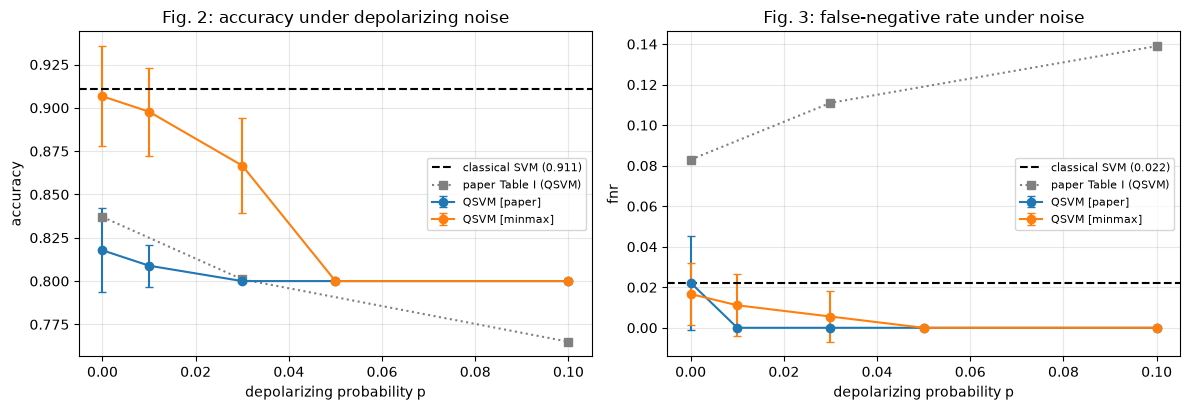

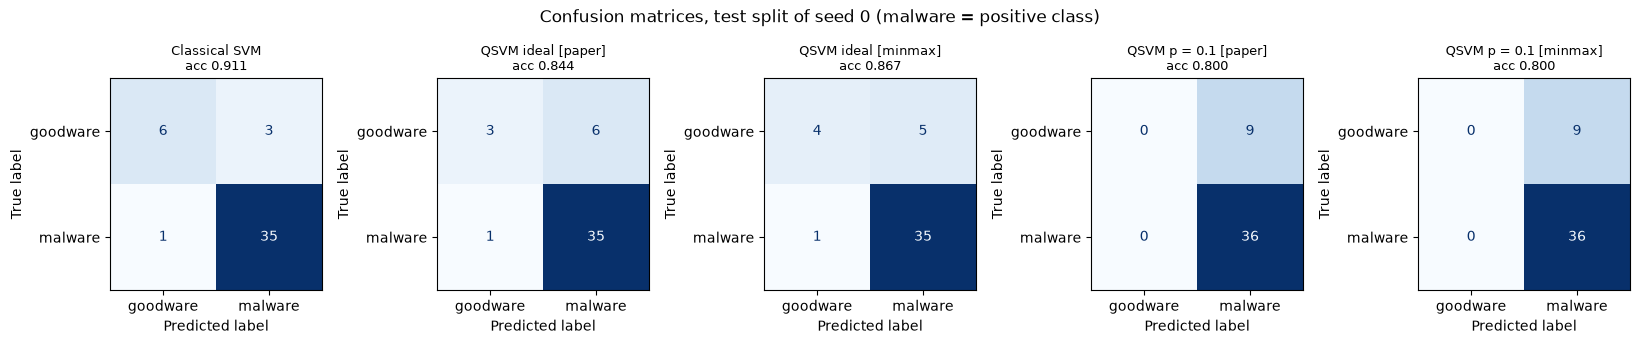

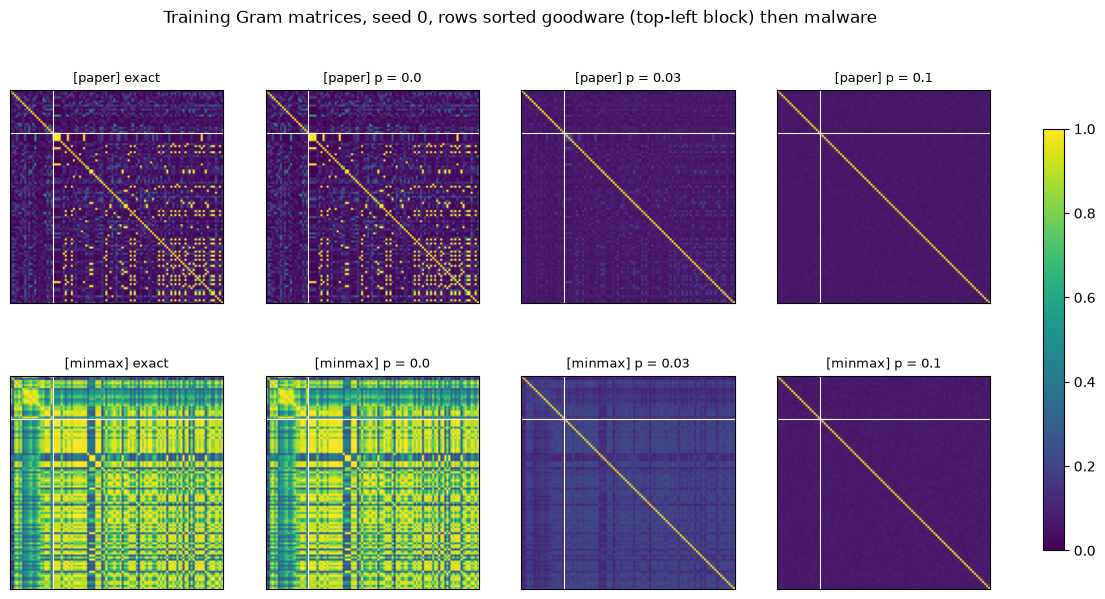

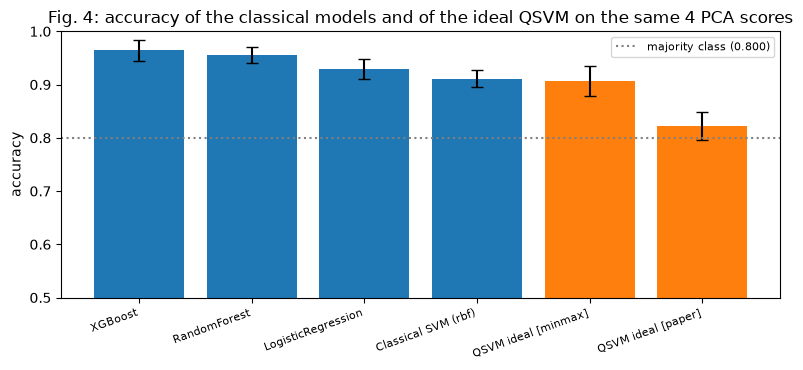

In [13]:
svm_mean = baseline_df[baseline_df.model == "Classical SVM (rbf)"][METRICS].mean()
svm_std = baseline_df[baseline_df.model == "Classical SVM (rbf)"][METRICS].std()
table1 = [dict(model="Classical SVM", **{m: svm_mean[m] for m in ["accuracy", "f1", "fnr", "auc"]})]
for mode in ANGLE_MODES:
    g = ideal_df[ideal_df.angle_mode == mode][METRICS].mean()
    table1.append(dict(model=f"QSVM ideal, exact kernel [{mode}]", **{m: g[m] for m in ["accuracy", "f1", "fnr", "auc"]}))
    for p in NOISE_LEVELS:
        g = noise_df[(noise_df.angle_mode == mode) & (noise_df.noise == p)][METRICS].mean()
        table1.append(dict(model=f"QSVM (p = {p:.2f}, {SHOTS} shots) [{mode}]", **{m: g[m] for m in ["accuracy", "f1", "fnr", "auc"]}))
table1 = pd.DataFrame(table1).set_index("model").round(3)
print("This notebook's Table I (means over seeds). Paper: SVM 0.904 / 0.926 / 0.056 / 0.950; QSVM 0.00: 0.837 / 0.882 / 0.083 / 0.890; "
      "0.03: 0.801 / 0.849 / 0.111 / 0.840; 0.10: 0.765 / 0.818 / 0.139 / 0.810")
display(table1)

PAPER_FIG = {0.00: (0.837, 0.083), 0.03: (0.801, 0.111), 0.10: (0.765, 0.139)}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, metric, title, paper_idx in [(axes[0], "accuracy", "Fig. 2: accuracy under depolarizing noise", 0), (axes[1], "fnr", "Fig. 3: false-negative rate under noise", 1)]:
    for mode in ANGLE_MODES:
        g = noise_df[noise_df.angle_mode == mode].groupby("noise")[metric].agg(["mean", "std"])
        ax.errorbar(g.index, g["mean"], yerr=g["std"].fillna(0), marker="o", capsize=3, label=f"QSVM [{mode}]")
    ax.axhline(svm_mean[metric], color="k", ls="--", label=f"classical SVM ({svm_mean[metric]:.3f})")
    ax.plot(list(PAPER_FIG), [v[paper_idx] for v in PAPER_FIG.values()], "s:", color="gray", label="paper Table I (QSVM)")
    ax.set_xlabel("depolarizing probability p"); ax.set_ylabel(metric); ax.set_title(title); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

s0 = SEEDS[0]; d0 = prepared[s0]; p_max = max(NOISE_LEVELS); mode0 = ANGLE_MODES[0]
panels = [("Classical SVM", baseline_preds[(s0, "Classical SVM (rbf)")])] + \
         [(f"QSVM ideal [{m}]", ideal_preds[(m, s0)]) for m in ANGLE_MODES] + \
         [(f"QSVM p = {p_max} [{m}]", noise_preds[(m, p_max, s0)]) for m in ANGLE_MODES]
fig, axes = plt.subplots(1, len(panels), figsize=(3.3 * len(panels), 3.4))
for ax, (name, pred) in zip(axes, panels):
    ConfusionMatrixDisplay(confusion_matrix(d0["y_te"], pred, labels=[0, 1]), display_labels=["goodware", "malware"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\nacc {accuracy_score(d0['y_te'], pred):.3f}", fontsize=9)
plt.suptitle(f"Confusion matrices, test split of seed {s0} (malware = positive class)"); plt.tight_layout(); plt.show()

order = np.argsort(d0["y_tr"], kind="stable"); n_good = int((d0["y_tr"] == 0).sum())
show_levels = [NOISE_LEVELS[0], NOISE_LEVELS[len(NOISE_LEVELS) // 2], NOISE_LEVELS[-1]]
fig, axes = plt.subplots(len(ANGLE_MODES), 1 + len(show_levels), figsize=(3.4 * (1 + len(show_levels)), 3.4 * len(ANGLE_MODES)), squeeze=False)
for r_, mode in enumerate(ANGLE_MODES):
    mats = [("exact", ideal_kernels[(mode, s0)][0])] + [(f"p = {p}", noise_kernels[(mode, p, s0)][0]) for p in show_levels]
    for ax, (name, K) in zip(axes[r_], mats):
        im = ax.imshow(K[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1); ax.axhline(n_good - 0.5, color="w", lw=0.8); ax.axvline(n_good - 0.5, color="w", lw=0.8)
        ax.set_title(f"[{mode}] {name}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, fraction=0.02); plt.suptitle(f"Training Gram matrices, seed {s0}, rows sorted goodware (top-left block) then malware"); plt.show()

fig4 = baseline_df[baseline_df.inputs == "4 PCA scores"].groupby("model")["accuracy"].agg(["mean", "std"])
for mode in ANGLE_MODES:
    g = ideal_df[ideal_df.angle_mode == mode]["accuracy"]; fig4.loc[f"QSVM ideal [{mode}]"] = [g.mean(), g.std()]
fig4 = fig4.sort_values("mean", ascending=False)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(fig4.index, fig4["mean"], yerr=fig4["std"].fillna(0), capsize=4, color=["tab:orange" if "QSVM" in i else "tab:blue" for i in fig4.index])
ax.axhline(majority, color="gray", ls=":", label=f"majority class ({majority:.3f})"); ax.set_ylim(0.5, 1.0); ax.set_ylabel("accuracy"); ax.legend(fontsize=8)
ax.set_title("Fig. 4: accuracy of the classical models and of the ideal QSVM on the same 4 PCA scores"); plt.xticks(rotation=20, ha="right", fontsize=8)
plt.tight_layout(); plt.show()

## 10. Table II and Fig. 5: how many principal components?

The paper repeats the ideal experiment with 2, 3, 4 and 6 principal components (= qubits) for the classical SVM and the
QSVM. With the exact statevector kernel this is cheap, so it runs for every seed here, in both encodings (for `minmax`
the per-seed scale chosen in Section 5b is reused).

This notebook's Table II (accuracy vs PCA components). Paper: classical 0.842 / 0.881 / 0.904 / 0.921, QSVM 0.783 / 0.817 / 0.837 / 0.865 for 2 / 3 / 4 / 6


mean                                                  std                                       
model      Classical SVM QSVM ideal [minmax] QSVM ideal [paper] Classical SVM QSVM ideal [minmax] QSVM ideal [paper]
components                                                                                                          
2                  0.809               0.804              0.796         0.020               0.010              0.010
3                  0.893               0.867              0.827         0.019               0.052              0.019
4                  0.911               0.907              0.822         0.016               0.029              0.027
6                  0.916               0.924              0.822         0.024               0.030              0.016

variance kept (training split, mean over seeds): {2: 0.484, 3: 0.565, 4: 0.624, 6: 0.712}


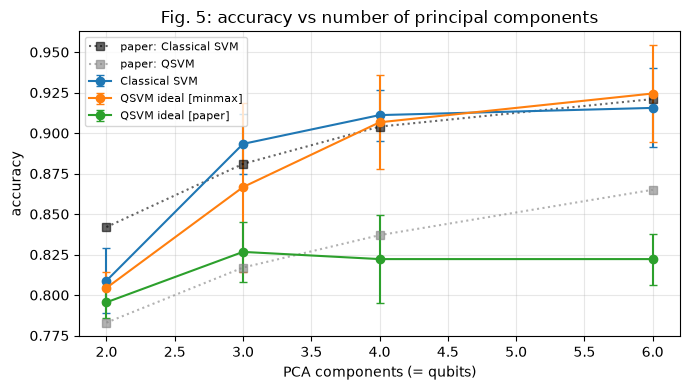

In [14]:
pca_rows = []
for k in PCA_GRID:
    fm_k = zz_feature_map(k, reps=FM_REPS, entanglement=ENTANGLEMENT); qk = FidelityStatevectorKernel(feature_map=fm_k)
    for s in SEEDS:
        d = prepare(s, n_components=k)
        svm = SVC(kernel="rbf", C=SVM_C, gamma=SVM_GAMMA, random_state=SEED).fit(d["P_tr"], d["y_tr"])
        pca_rows.append(dict(components=k, seed=s, model="Classical SVM", variance=d["pca"].explained_variance_ratio_.sum(),
                             **all_metrics(d["y_te"], svm.predict(d["P_te"]), svm.decision_function(d["P_te"]))))
        for mode in ANGLE_MODES:
            A_tr, A_te = angles(d, mode, best_scale[s] if mode == "minmax" else 1.0)
            K_tr, K_te = qk.evaluate(A_tr), qk.evaluate(A_te, A_tr)
            pred, r = qsvm_fit_eval(K_tr, K_te, d["y_tr"], d["y_te"])
            pca_rows.append(dict(components=k, seed=s, model=f"QSVM ideal [{mode}]", variance=d["pca"].explained_variance_ratio_.sum(), **{m: r[m] for m in METRICS}))
pca_df = pd.DataFrame(pca_rows)
table2 = pca_df.pivot_table(index="components", columns="model", values="accuracy", aggfunc=["mean", "std"]).round(3)
print("This notebook's Table II (accuracy vs PCA components). Paper: classical 0.842 / 0.881 / 0.904 / 0.921, QSVM 0.783 / 0.817 / 0.837 / 0.865 for 2 / 3 / 4 / 6")
display(table2)
print("variance kept (training split, mean over seeds):", pca_df.groupby("components")["variance"].mean().round(3).to_dict())

PAPER_T2 = {"Classical SVM": [0.842, 0.881, 0.904, 0.921], "QSVM": [0.783, 0.817, 0.837, 0.865]}
fig, ax = plt.subplots(figsize=(7, 4))
for model, g in pca_df.groupby("model"):
    gg = g.groupby("components")["accuracy"].agg(["mean", "std"])
    ax.errorbar(gg.index, gg["mean"], yerr=gg["std"].fillna(0), marker="o", capsize=3, label=model)
for model, vals in PAPER_T2.items():
    ax.plot([2, 3, 4, 6], vals, "s:", color="gray" if "QSVM" in model else "k", alpha=0.6, label=f"paper: {model}")
ax.set_xlabel("PCA components (= qubits)"); ax.set_ylabel("accuracy"); ax.set_title("Fig. 5: accuracy vs number of principal components"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 11. Paper versus this notebook

Each row is one number of the paper's Tables I-III. The verdict is **reproduced** when our value (mean over seeds, the
paper's encoding) is within 0.02 of the paper's (two accuracy points, 0.02 in F1 / FNR / AUC), **exceeded** when it is
more than 0.02 above, **not reached** when more than 0.02 below. The qualitative claims (which direction things move)
are checked separately. Where a comparison cannot be made (FAST_MODE skipped a noise level or a single seed makes a paired
test impossible) the verdict says so. The `minmax` encoding is shown as a second column but never used for the verdict,
because the paper did not do it.

In [15]:
TOL = 0.02
def verdict(paper, ours, tol=TOL):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)):
        return "not run here"
    return "reproduced" if abs(ours - paper) <= tol else ("exceeded" if ours > paper else "not reached")

rows = []
P1 = {"Classical SVM": (0.904, 0.926, 0.056, 0.950), "QSVM (0.00)": (0.837, 0.882, 0.083, 0.890), "QSVM (0.03)": (0.801, 0.849, 0.111, 0.840), "QSVM (0.10)": (0.765, 0.818, 0.139, 0.810)}
def noisy_mean(mode, p, metric):
    g = noise_df[(noise_df.angle_mode == mode) & (np.isclose(noise_df.noise, p))][metric]
    return float(g.mean()) if len(g) else np.nan
for model, vals in P1.items():
    for metric, pv in zip(["accuracy", "f1", "fnr", "auc"], vals):
        if model == "Classical SVM":
            ours, alt = float(svm_mean[metric]), np.nan
        elif model == "QSVM (0.00)":
            ours = float(ideal_df[ideal_df.angle_mode == "paper"][metric].mean()); alt = float(ideal_df[ideal_df.angle_mode == "minmax"][metric].mean()) if "minmax" in ANGLE_MODES else np.nan
        else:
            p = float(model[6:-1]); ours = noisy_mean("paper", p, metric); alt = noisy_mean("minmax", p, metric) if "minmax" in ANGLE_MODES else np.nan
        rows.append(dict(table="I", item=f"{model} {metric}", paper=pv, notebook=round(ours, 3) if not np.isnan(ours) else np.nan,
                         notebook_minmax=round(alt, 3) if not np.isnan(alt) else np.nan, verdict=verdict(pv, ours)))
for k, pc, pq in zip([2, 3, 4, 6], PAPER_T2["Classical SVM"], PAPER_T2["QSVM"]):
    c = float(pca_df[(pca_df.components == k) & (pca_df.model == "Classical SVM")]["accuracy"].mean())
    q = float(pca_df[(pca_df.components == k) & (pca_df.model == "QSVM ideal [paper]")]["accuracy"].mean())
    qm = float(pca_df[(pca_df.components == k) & (pca_df.model == "QSVM ideal [minmax]")]["accuracy"].mean()) if "minmax" in ANGLE_MODES else np.nan
    rows.append(dict(table="II", item=f"classical accuracy, {k} components", paper=pc, notebook=round(c, 3), notebook_minmax=np.nan, verdict=verdict(pc, c)))
    rows.append(dict(table="II", item=f"QSVM accuracy, {k} components", paper=pq, notebook=round(q, 3), notebook_minmax=round(qm, 3) if not np.isnan(qm) else np.nan, verdict=verdict(pq, q)))
st = stats_df[stats_df.qsvm_encoding == "paper"].iloc[0]
for item, pv, ours, ok in [("paired t-test p-value < 0.05 (t = 3.42, p = 0.012)", 0.012, st["t_pvalue"], (not np.isnan(st["t_pvalue"])) and st["t_pvalue"] < 0.05),
                           ("Cohen's d (1.21, large effect)", 1.21, st["cohens_d"], (not np.isnan(st["cohens_d"])) and st["cohens_d"] > 0.8),
                           ("Wilcoxon p-value < 0.05 (p = 0.031)", 0.031, st["wilcoxon_pvalue"], (not np.isnan(st["wilcoxon_pvalue"])) and st["wilcoxon_pvalue"] < 0.05)]:
    v = "cannot be checked (needs several seeds)" if np.isnan(ours) else ("reproduced (same conclusion)" if ok else "not reproduced (conclusion differs)")
    rows.append(dict(table="III", item=item, paper=pv, notebook=round(float(ours), 4) if not np.isnan(ours) else np.nan, notebook_minmax=np.nan, verdict=v))
comparison = pd.DataFrame(rows)
display(comparison)
print(comparison.groupby("table")["verdict"].value_counts().to_dict())

# qualitative claims
acc_by_p = noise_df[noise_df.angle_mode == "paper"].groupby("noise")["accuracy"].mean()
fnr_by_p = noise_df[noise_df.angle_mode == "paper"].groupby("noise")["fnr"].mean()
q_ideal = float(ideal_df[ideal_df.angle_mode == "paper"]["accuracy"].mean())
claims = [
    dict(claim="Classical SVM beats the ideal QSVM (0.904 vs 0.837, gap 6.7 points)", notebook=f"gap {svm_mean['accuracy'] - q_ideal:+.3f} (SVM {svm_mean['accuracy']:.3f}, QSVM {q_ideal:.3f})",
         verdict="reproduced (same direction)" if svm_mean["accuracy"] - q_ideal > 0.01 else "not reproduced"),
    dict(claim="QSVM accuracy decreases with increasing depolarizing noise (0.837 -> 0.765)", notebook=" -> ".join(f"{p:.2f}: {a:.3f}" for p, a in acc_by_p.items()),
         verdict="reproduced (same direction)" if acc_by_p.iloc[-1] < acc_by_p.iloc[0] - 0.01 else ("not reproduced (flat: the kernel is already identity-like without noise)" if abs(acc_by_p.iloc[-1] - acc_by_p.iloc[0]) <= 0.01 else "not reproduced (opposite direction)")),
    dict(claim="QSVM FNR rises with moderate noise (0.083 -> 0.111 -> 0.139)", notebook=" -> ".join(f"{p:.2f}: {f:.3f}" for p, f in fnr_by_p.items()),
         verdict="reproduced (same direction)" if fnr_by_p.iloc[-1] > fnr_by_p.iloc[0] + 0.01 else ("not reproduced (FNR stays at 0: the noisy QSVM calls everything malware)" if fnr_by_p.max() < 0.01 else "not reproduced")),
    dict(claim="Classical SVM FNR 5-6 %", notebook=f"{svm_mean['fnr']:.3f} +- {svm_std['fnr'] if not np.isnan(svm_std['fnr']) else 0:.3f}", verdict=verdict(0.056, float(svm_mean["fnr"]))),
    dict(claim="Fig. 4: classical SVM best, then random forest and XGBoost; QSVM below every classical model",
         notebook="; ".join(f"{i}: {v:.3f}" for i, v in fig4["mean"].items()),
         verdict="reproduced" if fig4.index[0] == "Classical SVM (rbf)" and all(fig4.loc[i, "mean"] > q_ideal for i in fig4.index if "QSVM" not in i) else "partly: see ordering"),
    dict(claim="PCA with 4 components keeps 59.4 % of the variance", notebook=f"{ev150.sum():.1%} with the paper's all-150 fit; {np.mean([prepared[s]['pca'].explained_variance_ratio_.sum() for s in SEEDS]):.1%} fitted on the training split",
         verdict="reproduced (paper's fit); the leakage-free fit keeps more"),
]
if "minmax" in ANGLE_MODES:
    q_mm = float(ideal_df[ideal_df.angle_mode == "minmax"]["accuracy"].mean())
    claims.append(dict(claim="(not in the paper) with [0, pi] angles and a validated bandwidth the QSVM is competitive", notebook=f"QSVM [minmax] ideal {q_mm:.3f} vs SVM {svm_mean['accuracy']:.3f}",
                       verdict="QSVM within 2 points of the SVM" if abs(q_mm - svm_mean["accuracy"]) <= 0.02 else ("QSVM ahead" if q_mm > svm_mean["accuracy"] else "SVM still ahead")))
display(pd.DataFrame(claims))

,table,item,paper,notebook,notebook_minmax,verdict
0,I,Classical SVM accuracy,0.904,0.9110,NaN,reproduced
1,I,Classical SVM f1,0.926,0.9460,NaN,exceeded
2,I,Classical SVM fnr,0.056,0.0220,NaN,not reached
3,I,Classical SVM auc,0.950,0.9480,NaN,reproduced
4,I,QSVM (0.00) accuracy,0.837,0.8220,0.907,reproduced
5,I,QSVM (0.00) f1,0.882,0.8980,0.944,reproduced
6,I,QSVM (0.00) fnr,0.083,0.0220,0.017,not reached
7,I,QSVM (0.00) auc,0.890,0.8870,0.930,reproduced
8,I,QSVM (0.03) accuracy,0.801,0.8000,0.867,reproduced
9,I,QSVM (0.03) f1,0.849,0.8890,0.923,exceeded


{('I', 'reproduced'): 6, ('I', 'not reached'): 6, ('I', 'exceeded'): 4, ('II', 'reproduced'): 6, ('II', 'not reached'): 2, ('III', 'reproduced (same conclusion)'): 2, ('III', 'not reproduced (conclusion differs)'): 1}


,claim,notebook,verdict
0,Classical SVM beats the ideal QSVM (0.904 vs 0...,"gap +0.089 (SVM 0.911, QSVM 0.822)",reproduced (same direction)
1,QSVM accuracy decreases with increasing depola...,0.00: 0.818 -> 0.01: 0.809 -> 0.03: 0.800 -> 0...,reproduced (same direction)
2,QSVM FNR rises with moderate noise (0.083 -> 0...,0.00: 0.022 -> 0.01: 0.000 -> 0.03: 0.000 -> 0...,not reproduced
3,Classical SVM FNR 5-6 %,0.022 +- 0.012,not reached
4,"Fig. 4: classical SVM best, then random forest...",XGBoost: 0.964; RandomForest: 0.956; LogisticR...,partly: see ordering
5,PCA with 4 components keeps 59.4 % of the vari...,59.4% with the paper's all-150 fit; 62.4% fitt...,reproduced (paper's fit); the leakage-free fit...
6,"(not in the paper) with [0, pi] angles and a v...",QSVM [minmax] ideal 0.907 vs SVM 0.911,QSVM within 2 points of the SVM


## Reading the paper critically

**The quantum kernel the paper trained is close to an identity matrix.** The paper's code feeds the raw PCA scores to the
`ZZFeatureMap`. Standardised 241-dimensional binary vectors give scores with standard deviations of 2 to 7 and a range of
about -10 to +40 (Section 3), and the map rotates by $2x_i$ and $2(\pi - x_i)(\pi - x_j)$, so two apps that differ by a
fraction of a unit already have almost orthogonal states. Section 5 shows the consequence: the mean off-diagonal kernel
value is about 0.11, a little over half of the training apps become support vectors (56 of 105), and for any test app that
is far from everything the SVM can only fall back on the majority class (malware). That is why the "ideal QSVM" sits at 82 % here (paper 83.7 %) with a false-positive rate of about 0.8: the test split is 80 %
malware, so the majority-class rule alone scores 0.80 with FNR 0, and the QSVM adds only a handful of correct goodware calls to it. The noise sweep makes the same point from the other side: depolarizing
noise shrinks all off-diagonal entries towards the $1/16$ floor, which changes a near-identity kernel very little, so the
QSVM's accuracy in this notebook (0.82 at p = 0, 0.80 from p = 0.03 on, i.e. the majority-class floor) moves far less with `p` than the paper's Fig. 2 (0.837 to 0.765, below the floor) (the paper's noise script also used
`reps = 1`, a different circuit from the one in its text). The false-negative-rate story of the paper's Fig. 3 (FNR rising to 13.9 %) is
not reproduced: with this kernel, noise pushes the classifier towards "everything is malware", so the FNR falls to 0 and the false-positive rate rises to 1,
which is the 'biased classifier' behaviour the paper's conclusion mentions only for extreme noise. The `minmax` encoding with a bandwidth chosen on training data
only (Section 5b) gives a QSVM at the level of the classical SVM (0.907 vs 0.911 accuracy, paired t-test p = 0.75), which then also degrades with noise (0.907 at p = 0, 0.867 at p = 0.03, the 0.80 floor from p = 0.05); the gap the paper measures is a gap between an untuned
feature-map scale and a sensibly scaled RBF kernel, not between quantum and classical kernels.

**The statistical test compares five numbers each of which is a count out of 45.** The test split has 45 apps (36 malware,
9 goodware), so accuracy moves in steps of 2.2 points and a two-sided Wilcoxon test with five pairs cannot produce a p-value
below 0.0625; the paper's 0.031 is a one-sided value. A paired t-test on five seeds of the same 150 apps also does not
measure what a reader would hope: the five splits reuse the same apps, so the "runs" are not independent samples of
Android malware, only re-shufflings of one small subset. The 150-app subset itself (3 % of TUANDROMD) is the real
limitation; a classical SVM on all 241 features of the same 105 training apps already reaches about 0.95 (Section 4: 0.947 against 0.911 on four components), and random forest and XGBoost on the four components (0.956, 0.964) beat the
RBF-SVM, contrary to the ordering in the paper's Fig. 4.

**PCA was fitted on the test apps.** The public code standardises and projects all 150 apps before splitting. That is how
the paper gets exactly 59.4 % variance (we reproduce that number); with the projection fitted on the 105 training apps only
the kept variance is 61 to 64 % depending on the seed and nothing else changes much, so this is a protocol flaw with little effect here, but it
is the kind of leakage the notebook's `prepare()` is written to avoid.

**"Noise-aware" and "hybrid" describe the evaluation, not the method.** Nothing in the pipeline adapts to noise (no error
mitigation, no noise-aware kernel alignment, no re-training on noisy kernels); the hybrid is the ordinary
precomputed-kernel SVM. The paper is an honest robustness study of a standard QSVM, and its conclusion ("classical
kernel-based techniques may still be preferred") is right for the configuration it tested. The table rows that landed
under Table III in the PDF (QSVM 0.00 and 0.03) belong to Table I.

**What this notebook adds.** Every number of the paper is re-computed on the same subset, with leakage-free preprocessing,
with both the paper's angle encoding and a validated one, with Aer's noise model checked against Aer's own counts, and with
the Gram-matrix eigenvalues and off-diagonal statistics that explain the behaviour. The verdict table in Section 11 says
which of the paper's numbers hold up.

## Exercises

1. **Bandwidth.** In `SCALE_GRID`, add 0.02 and 2.0 and rerun Sections 5b and 6. Plot the inner-validation accuracy and
   the mean off-diagonal kernel value against the scale. Where does the kernel become identity-like, and what happens to
   the number of support vectors?
2. **Noise where it hurts.** Run the noise sweep with `ANGLE_MODES = ["minmax"]` only and `NOISE_LEVELS = [0, 0.02, 0.05,
   0.10, 0.20, 0.30]`. At which `p` does the QSVM fall to the majority-class accuracy, and does the FNR go up (missed
   malware) or down (everything called malware) on the way? Compare with the paper's reading of Fig. 3.
3. **Shots.** Set `SHOTS = 128` and then `SHOTS = None` (exact noisy probabilities, no sampling). How much of the
   degradation at `p = 0` is shot noise, how much is gate noise? Look at `min_eig_raw` to see how much the PSD clipping has
   to repair in each case.
4. **The circuit in the code versus the circuit in the paper.** Set `FM_REPS = 1` (the paper's noise script) and rerun the
   sweep. Does one repetition make the kernel smoother or rougher, and does the accuracy-vs-noise curve get closer to the
   paper's Fig. 2?
5. **Statistics.** Replace the five fixed seeds by 30 random splits and recompute the paired t-test and the Wilcoxon test
   (two-sided). Then repeat with a 150-app subset drawn with a different `SUBSET_SEED`. Is the classical-vs-quantum gap
   stable across subsets, and is the paper's effect size (Cohen's d = 1.21) a property of the models or of the subset?